# TP 4 — Arbre de décision
**Machine Learning · Apprentissage supervisé · Classification et régression**

Ce TP reprend les exemples de la présentation :

| Exemple | Diapos | Problème |
|---|---|---|
| Exemple 1 | 34 – 36 | Classification binaire (Gini, entropie) : va-t-on jouer au tennis ? (8 jours) |
| Exemple 2 | 37 | Régression : ventes de glaces selon la température (SSE) |
| Exemple 3 | 38 – 39 | Arbre multibranches (ID3) : tennis sur 14 jours |

**Objectifs** : programmer **en Python pur** l’entropie, le gain, la recherche de la meilleure question et la construction récursive de l’arbre  ; puis refaire les mêmes exemples avec **scikit-learn** et comparer les deux implémentations (`DecisionTreeClassifier`, `DecisionTreeRegressor`, `mutual_info_classif`).

## Rappel de cours

L’arbre pose des questions oui / non successives. Il n’a **pas de poids** : il apprend **ses questions** (variable + seuil) et **ses feuilles**.

Pour choisir une question, on mesure le **mélange** (l’impureté) de chaque groupe. Deux mesures sont possibles :

- **Entropie** d’un groupe : $H = -\sum_k p_k \log_2 p_k$ (0 = groupe pur ; 1 = moitié-moitié avec 2 classes)
- **Indice de Gini** d’un groupe : $G = 1 - \sum_k p_k^2$ (0 = groupe pur ; 0,5 = moitié-moitié avec 2 classes)
  - Exemple (8 jours, 4 Oui / 4 Non) : $G = 1 - (0{,}5^2 + 0{,}5^2) = 0{,}5$
  - Groupe {J1, J3, J6, J7, J8} (4 Oui / 1 Non) : $G = 1 - (0{,}8^2 + 0{,}2^2) = 0{,}32$

  ($p_k$ = proportion de la classe $k$ dans le groupe)

- **Gain d’une question** (même formule avec l’entropie ou avec Gini) :
$$\text{Gain} = I(\text{parent}) - \sum_g \frac{n_g}{n}\,I(g) \qquad \text{avec } I = H \text{ (entropie) ou } I = G \text{ (Gini)}$$
- **Entropie ou Gini ?** Les deux mesurent la même chose et donnent en général le **même arbre** (c’est le cas sur notre exemple du tennis). Gini est un peu plus rapide à calculer (pas de logarithme) : c’est le critère **par défaut de scikit-learn** (`criterion="gini"`). L’entropie est utilisée par ID3 et dans notre calcul à la main (`criterion="entropy"`).
- **Seuils testés** pour une variable numérique : milieux entre deux valeurs observées triées
- **Construction gloutonne** : à chaque nœud on garde la question au **plus grand gain**, puis on recommence dans chaque groupe, jusqu’à des groupes purs (ou une profondeur maximale)
- **Régression** : on remplace l’entropie (ou Gini) par la **SSE** $= \sum (y - \bar y_{\text{groupe}})^2$ ; chaque feuille prédit la **moyenne** de son groupe

In [1]:
import math

---
# Partie A — Implémentation from scratch (Python pur)

## Exemple 1 : va-t-on jouer au tennis ?

| Jour | Ciel | Humidité | Vent | On joue ? |
|---|---|---|---|---|
| J1 | Soleil | 65 % | Faible | Oui |
| J2 | Soleil | 90 % | Faible | Non |
| J3 | Pluie | 70 % | Faible | Oui |
| J4 | Soleil | 85 % | Faible | Non |
| J5 | Pluie | 80 % | Fort | Non |
| J6 | Soleil | 70 % | Fort | Non |
| J7 | Pluie | 60 % | Faible | Oui |
| J8 | Soleil | 75 % | Faible | Oui |

In [2]:
jours = [
    {"jour": "J1", "ciel": "Soleil", "humidite": 65, "vent": "Faible", "joue": "Oui"},
    {"jour": "J2", "ciel": "Soleil", "humidite": 90, "vent": "Faible", "joue": "Non"},
    {"jour": "J3", "ciel": "Pluie",  "humidite": 70, "vent": "Faible", "joue": "Oui"},
    {"jour": "J4", "ciel": "Soleil", "humidite": 85, "vent": "Faible", "joue": "Non"},
    {"jour": "J5", "ciel": "Pluie",  "humidite": 80, "vent": "Fort",   "joue": "Non"},
    {"jour": "J6", "ciel": "Soleil", "humidite": 70, "vent": "Fort",   "joue": "Non"},
    {"jour": "J7", "ciel": "Pluie",  "humidite": 60, "vent": "Faible", "joue": "Oui"},
    {"jour": "J8", "ciel": "Soleil", "humidite": 75, "vent": "Faible", "joue": "Oui"},
]

### Question 1 — Entropie globale
**Réponse.** 4 Oui et 4 Non : $p = 0{,}5$ pour chaque classe, et $\log_2(0{,}5) = -1$.
$$H(S) = -0{,}5 \times (-1) - 0{,}5 \times (-1) = 1{,}00$$
C’est le mélange maximal : avec 4 Oui / 4 Non, on ne peut rien prédire.

In [3]:
def entropie(etiquettes):
    n = len(etiquettes)
    if n == 0:
        return 0.0
    h = 0.0
    for classe in set(etiquettes):
        p = etiquettes.count(classe) / n
        h -= p * math.log2(p)
    return h

H_S = entropie([j["joue"] for j in jours])
print(f"Entropie globale H(S) = {H_S:.3f}")

Entropie globale H(S) = 1.000


### Question 2 — Gain de chaque question à la racine
 Une question coupe les jours en un groupe « oui » et un groupe « non ». On calcule l’entropie de chaque groupe, la moyenne pondérée, puis le gain. Les questions possibles sont :
- « Ciel = Soleil ? » et « Vent fort ? » (variables à catégories) ;
- « Humidité ≤ t ? » avec $t$ = milieu entre deux humidités observées : 62,5 ; 67,5 ; 72,5 ; 77,5 ; 82,5 ; 87,5.

In [4]:
def questions_possibles(donnees):
    qs = [("ciel = Soleil ?", lambda j: j["ciel"] == "Soleil"),
          ("vent fort ?",     lambda j: j["vent"] == "Fort")]
    valeurs = sorted(set(j["humidite"] for j in donnees))
    for a, b in zip(valeurs, valeurs[1:]):
        t = (a + b) / 2
        qs.append((f"humidité ≤ {t} ?", lambda j, t=t: j["humidite"] <= t))
    return qs

def gain(donnees, test, cible="joue"):
    oui = [j for j in donnees if test(j)]
    non = [j for j in donnees if not test(j)]
    n = len(donnees)
    h_parent = entropie([j[cible] for j in donnees])
    h_oui, h_non = entropie([j[cible] for j in oui]), entropie([j[cible] for j in non])
    moyenne = len(oui) / n * h_oui + len(non) / n * h_non
    return h_parent - moyenne, oui, non, h_oui, h_non, moyenne

print(f"{'Question':<22}{'groupe oui':<26}{'H(oui)':>7}  {'groupe non':<26}{'H(non)':>7}{'moy.':>7}{'gain':>7}")
gains_racine = {}
for nom, test in questions_possibles(jours):
    g, oui, non, ho, hn, moy = gain(jours, test)
    gains_racine[nom] = g
    print(f"{nom:<22}{', '.join(j['jour'] for j in oui):<26}{ho:>7.3f}  {', '.join(j['jour'] for j in non):<26}{hn:>7.3f}{moy:>7.3f}{g:>7.3f}")

Question              groupe oui                 H(oui)  groupe non                 H(non)   moy.   gain
ciel = Soleil ?       J1, J2, J4, J6, J8          0.971  J3, J5, J7                  0.918  0.951  0.049
vent fort ?           J5, J6                      0.000  J1, J2, J3, J4, J7, J8      0.918  0.689  0.311
humidité ≤ 62.5 ?     J7                          0.000  J1, J2, J3, J4, J5, J6, J8  0.985  0.862  0.138
humidité ≤ 67.5 ?     J1, J7                      0.000  J2, J3, J4, J5, J6, J8      0.918  0.689  0.311
humidité ≤ 72.5 ?     J1, J3, J6, J7              0.811  J2, J4, J5, J8              0.811  0.811  0.189
humidité ≤ 77.5 ?     J1, J3, J6, J7, J8          0.722  J2, J4, J5                  0.000  0.451  0.549
humidité ≤ 82.5 ?     J1, J3, J5, J6, J7, J8      0.918  J2, J4                      0.000  0.689  0.311
humidité ≤ 87.5 ?     J1, J3, J4, J5, J6, J7, J8  0.985  J2                          0.000  0.862  0.138


In [5]:
meilleure = max(gains_racine, key=gains_racine.get)
print(f"Meilleure question à la racine : {meilleure}  (gain = {gains_racine[meilleure]:.3f})")

Meilleure question à la racine : humidité ≤ 77.5 ?  (gain = 0.549)


### Question 2 — Même calcul avec l’indice de Gini
**Réponse.** On remplace l’entropie par $G = 1 - \sum_k p_k^2$ dans le calcul du gain. Au départ, $G = 0{,}5$ (4 Oui / 4 Non). La meilleure question reste « Humidité ≤ 77,5 ? » : gain de Gini $= 0{,}5 - \frac{5}{8}\times 0{,}32 - \frac{3}{8}\times 0 = 0{,}30$.

In [6]:
def gini(etiquettes):
    n = len(etiquettes)
    if n == 0:
        return 0.0
    return 1 - sum((etiquettes.count(c) / n) ** 2 for c in set(etiquettes))

def gain_gini(donnees, test, cible="joue"):
    oui = [j[cible] for j in donnees if test(j)]
    non = [j[cible] for j in donnees if not test(j)]
    n = len(donnees)
    return gini([j[cible] for j in donnees]) - len(oui) / n * gini(oui) - len(non) / n * gini(non)

print(f"Gini de départ : {gini([j['joue'] for j in jours]):.3f}")
gains_gini_racine = {}
for nom, test in questions_possibles(jours):
    gains_gini_racine[nom] = gain_gini(jours, test)
    print(f"{nom:<22} gain Gini = {gains_gini_racine[nom]:.3f}   (gain entropie = {gains_racine[nom]:.3f})")
meilleure_gini = max(gains_gini_racine, key=gains_gini_racine.get)
print(f"\nMeilleure question avec Gini : {meilleure_gini}  (même question qu'avec l'entropie : {meilleure_gini == meilleure})")

Gini de départ : 0.500
ciel = Soleil ?        gain Gini = 0.033   (gain entropie = 0.049)
vent fort ?            gain Gini = 0.167   (gain entropie = 0.311)
humidité ≤ 62.5 ?      gain Gini = 0.071   (gain entropie = 0.138)
humidité ≤ 67.5 ?      gain Gini = 0.167   (gain entropie = 0.311)
humidité ≤ 72.5 ?      gain Gini = 0.125   (gain entropie = 0.189)
humidité ≤ 77.5 ?      gain Gini = 0.300   (gain entropie = 0.549)
humidité ≤ 82.5 ?      gain Gini = 0.167   (gain entropie = 0.311)
humidité ≤ 87.5 ?      gain Gini = 0.071   (gain entropie = 0.138)

Meilleure question avec Gini : humidité ≤ 77.5 ?  (même question qu'avec l'entropie : True)


### Question 3 — Niveau 2 : recommencer dans le groupe « Humidité ≤ 77,5 % »
 Le groupe {J1, J3, J6, J7, J8} contient 4 Oui / 1 Non : $H = 0{,}722$. On teste à nouveau toutes les questions. « Vent fort ? » sépare parfaitement le groupe (deux groupes purs) : gain $= 0{,}722 - 0 = 0{,}722$.

In [7]:
groupe = [j for j in jours if j["humidite"] <= 77.5]
print(f"Entropie du groupe : {entropie([j['joue'] for j in groupe]):.3f}")
gains_n2 = {}
for nom, test in questions_possibles(groupe):
    gains_n2[nom] = gain(groupe, test)[0]
    print(f"{nom:<22} gain = {gains_n2[nom]:.3f}")
print("Meilleure question au niveau 2 :", max(gains_n2, key=gains_n2.get))

Entropie du groupe : 0.722
ciel = Soleil ?        gain = 0.171
vent fort ?            gain = 0.722
humidité ≤ 62.5 ?      gain = 0.073
humidité ≤ 67.5 ?      gain = 0.171
humidité ≤ 72.5 ?      gain = 0.073
Meilleure question au niveau 2 : vent fort ?


### Question 4 — Construire l’arbre complet automatiquement, puis prédire
 On écrit une fonction **récursive** : si le groupe est pur, on crée une feuille (classe majoritaire) ; sinon on choisit la question au plus grand gain et on recommence dans chaque sous-groupe. L’arbre obtenu : *Humidité ≤ 77,5 ?* → non : **NON** ; oui : *Vent fort ?* → oui : **NON**, non : **OUI**.

Demain : Soleil, humidité 72 %, vent fort → 72 ≤ 77,5 → vent fort → **on ne joue pas**.

In [8]:
def majoritaire(etiquettes):
    return max(set(etiquettes), key=etiquettes.count)

def construire(donnees, profondeur=0, prof_max=10):
    etiquettes = [j["joue"] for j in donnees]
    if entropie(etiquettes) == 0 or profondeur == prof_max:
        return {"feuille": majoritaire(etiquettes), "jours": [j["jour"] for j in donnees]}
    meilleur = max(questions_possibles(donnees), key=lambda q: gain(donnees, q[1])[0])
    nom, test = meilleur
    oui = [j for j in donnees if test(j)]
    non = [j for j in donnees if not test(j)]
    return {"question": nom, "test": test,
            "oui": construire(oui, profondeur + 1, prof_max),
            "non": construire(non, profondeur + 1, prof_max)}

def afficher_arbre(noeud, indent=""):
    if "feuille" in noeud:
        print(f"{indent}→ {noeud['feuille'].upper()}  ({', '.join(noeud['jours'])})")
        return
    print(f"{indent}{noeud['question']}")
    print(f"{indent}  oui :"); afficher_arbre(noeud["oui"], indent + "    ")
    print(f"{indent}  non :"); afficher_arbre(noeud["non"], indent + "    ")

def predire(noeud, jour):
    while "feuille" not in noeud:
        noeud = noeud["oui"] if noeud["test"](jour) else noeud["non"]
    return noeud["feuille"]

arbre = construire(jours)
afficher_arbre(arbre)
demain = {"ciel": "Soleil", "humidite": 72, "vent": "Fort"}
print("\nDemain (Soleil, 72 %, vent fort) → on joue ?", predire(arbre, demain))
bien_classes = sum(predire(arbre, j) == j["joue"] for j in jours)
print(f"Jours d'entraînement bien classés : {bien_classes} / {len(jours)}")

humidité ≤ 77.5 ?
  oui :
    vent fort ?
      oui :
        → NON  (J6)
      non :
        → OUI  (J1, J3, J7, J8)
  non :
    → NON  (J2, J4, J5)

Demain (Soleil, 72 %, vent fort) → on joue ? Non
Jours d'entraînement bien classés : 8 / 8


## Exemple 2 : arbre de régression — ventes de glaces

| Température (°C) | 12 | 18 | 26 | 32 |
|---|---|---|---|---|
| Ventes (TND) | 40 | 60 | 200 | 240 |

### Question 5 — Choisir la meilleure coupure avec la SSE
Seuils testés : 15, 22 et 29 °C (milieux). Pour chaque seuil, SSE totale = SSE gauche + SSE droite :
- T ≤ 15 : 0 + 17 867 = 17 867
- T ≤ 22 : 200 + 800 = **1 000** ← la plus petite
- T ≤ 29 : 15 200 + 0 = 15 200

Feuilles : moyenne de chaque groupe, 50 TND (froid) et 220 TND (chaud). À 28 °C → **220 TND**.

In [9]:
temperatures = [12, 18, 26, 32]
ventes = [40, 60, 200, 240]

def sse(valeurs):
    if not valeurs:
        return 0.0
    m = sum(valeurs) / len(valeurs)
    return sum((v - m) ** 2 for v in valeurs)

resultats = {}
for a, b in zip(temperatures, temperatures[1:]):
    t = (a + b) / 2
    gauche = [v for x, v in zip(temperatures, ventes) if x <= t]
    droite = [v for x, v in zip(temperatures, ventes) if x > t]
    resultats[t] = (sse(gauche) + sse(droite), gauche, droite)
    print(f"T ≤ {t} : gauche {gauche} SSE = {sse(gauche):.0f} | droite {droite} SSE = {sse(droite):.0f} | total = {resultats[t][0]:.0f}")

t_best = min(resultats, key=lambda t: resultats[t][0])
gauche, droite = resultats[t_best][1], resultats[t_best][2]
feuille_g, feuille_d = sum(gauche) / len(gauche), sum(droite) / len(droite)
print(f"\nMeilleure coupure : T ≤ {t_best} °C → feuilles {feuille_g} TND et {feuille_d} TND")
prediction_28 = feuille_g if 28 <= t_best else feuille_d
print(f"Ventes prédites à 28 °C : {prediction_28} TND")

T ≤ 15.0 : gauche [40] SSE = 0 | droite [60, 200, 240] SSE = 17867 | total = 17867
T ≤ 22.0 : gauche [40, 60] SSE = 200 | droite [200, 240] SSE = 800 | total = 1000
T ≤ 29.0 : gauche [40, 60, 200] SSE = 15200 | droite [240] SSE = 0 | total = 15200

Meilleure coupure : T ≤ 22.0 °C → feuilles 50.0 TND et 220.0 TND
Ventes prédites à 28 °C : 220.0 TND


## Exemple 3 : arbre multibranches ID3 — tennis sur 14 jours

ID3 crée **une branche par valeur** de la variable choisie (et non deux branches oui / non).

In [1]:
lignes = '''soleil chaud haute faible non
soleil chaud haute fort non
couvert chaud haute faible oui
pluie doux haute faible oui
pluie frais normale faible oui
pluie frais normale fort non
couvert frais normale fort oui
soleil doux haute faible non
soleil frais normale faible oui
pluie doux normale faible oui
soleil doux normale fort oui
couvert doux haute fort oui
couvert chaud normale faible oui
pluie doux haute fort non'''
variables = ["ciel", "temperature", "humidite", "vent"]
jours14 = []
for i, l in enumerate(lignes.split("\n"), start=1):
    v = l.split()
    jours14.append({"jour": f"J{i}", "ciel": v[0], "temperature": v[1], "humidite": v[2], "vent": v[3], "jouer": v[4]})
print(len(jours14), "jours ;", sum(j["jouer"] == "oui" for j in jours14), "oui /", sum(j["jouer"] == "non" for j in jours14), "non")

14 jours ; 9 oui / 5 non


### Question 6 — Entropie de départ et gain de chaque variable

- Départ, 9 oui / 5 non : $H = -\frac{9}{14}\log_2\frac{9}{14} - \frac{5}{14}\log_2\frac{5}{14} = 0{,}940$
- Ciel : soleil (2/3) → 0,971 ; couvert (4/0) → 0 ; pluie (3/2) → 0,971 → gain = 0,940 − 0,694 = **0,247**
- Humidité 0,152 ; Vent 0,048 ; Température 0,029 → la racine est **Ciel**.

In [11]:
def gain_multibranches(donnees, variable, cible="jouer"):
    n = len(donnees)
    h_parent = entropie([j[cible] for j in donnees])
    moyenne = 0.0
    for valeur in set(j[variable] for j in donnees):
        sous = [j[cible] for j in donnees if j[variable] == valeur]
        moyenne += len(sous) / n * entropie(sous)
    return h_parent - moyenne

print(f"Entropie de départ (14 jours) : {entropie([j['jouer'] for j in jours14]):.3f}")
gains14 = {v: gain_multibranches(jours14, v) for v in variables}
for v in sorted(gains14, key=gains14.get, reverse=True):
    print(f"gain {v:<12} = {gains14[v]:.3f}")
print("Racine choisie :", max(gains14, key=gains14.get))

Entropie de départ (14 jours) : 0.940
gain ciel         = 0.247
gain humidite     = 0.152
gain vent         = 0.048
gain temperature  = 0.029
Racine choisie : ciel


### Question 7 — Construire l’arbre ID3 complet
 Dans la branche *couvert* (4 oui / 0 non), le groupe est pur : feuille **OUI**. Dans *soleil*, la meilleure variable est **Humidité** (gain 0,971) ; dans *pluie*, c’est **Vent** (gain 0,971). Tous les groupes sont alors purs : 2 niveaux, 5 feuilles. *Pluie + vent faible → on joue.*

In [12]:
def id3(donnees, variables, cible="jouer"):
    etiquettes = [j[cible] for j in donnees]
    if entropie(etiquettes) == 0 or not variables:
        return majoritaire(etiquettes)
    meilleure = max(variables, key=lambda v: gain_multibranches(donnees, v, cible))
    restantes = [v for v in variables if v != meilleure]
    return {meilleure: {valeur: id3([j for j in donnees if j[meilleure] == valeur], restantes, cible)
                        for valeur in sorted(set(j[meilleure] for j in donnees))}}

def afficher_id3(noeud, indent=""):
    if isinstance(noeud, str):
        print(indent + "→ " + noeud.upper()); return
    (var, branches), = noeud.items()
    for valeur, sous in branches.items():
        print(f"{indent}{var} = {valeur}")
        afficher_id3(sous, indent + "    ")

def predire_id3(noeud, jour):
    while not isinstance(noeud, str):
        (var, branches), = noeud.items()
        noeud = branches[jour[var]]
    return noeud

arbre_id3 = id3(jours14, variables)
afficher_id3(arbre_id3)
sol = [j for j in jours14 if j["ciel"] == "soleil"]; plu = [j for j in jours14 if j["ciel"] == "pluie"]
print(f"Gain humidité (branche soleil) : {gain_multibranches(sol, 'humidite'):.3f}")
print(f"Gain vent (branche pluie)      : {gain_multibranches(plu, 'vent'):.3f}")
print(f"Jours bien classés : {sum(predire_id3(arbre_id3, j) == j['jouer'] for j in jours14)} / {len(jours14)}")
print("Pluie + vent faible →", predire_id3(arbre_id3, {"ciel": "pluie", "vent": "faible", "humidite": "haute", "temperature": "doux"}))

ciel = couvert
    → OUI
ciel = pluie
    vent = faible
        → OUI
    vent = fort
        → NON
ciel = soleil
    humidite = haute
        → NON
    humidite = normale
        → OUI
Gain humidité (branche soleil) : 0.971
Gain vent (branche pluie)      : 0.971
Jours bien classés : 14 / 14
Pluie + vent faible → oui


---
# Partie B — Les mêmes exemples avec scikit-learn

### Question 8 — `DecisionTreeClassifier` sur les 8 jours
 scikit-learn ne travaille qu’avec des nombres : on code *Ciel = Soleil* et *Vent fort* en 0 / 1 . Avec `criterion="entropy"`, on doit obtenir le même arbre. Avec `"gini"`, le critère par défaut, l’arbre est ici le même aussi.

|--- humidite <= 77.50
|   |--- vent_fort <= 0.50
|   |   |--- class: Oui
|   |--- vent_fort >  0.50
|   |   |--- class: Non
|--- humidite >  77.50
|   |--- class: Non

Demain → Non
Avec Gini, même racine : |--- humidite <= 77.50


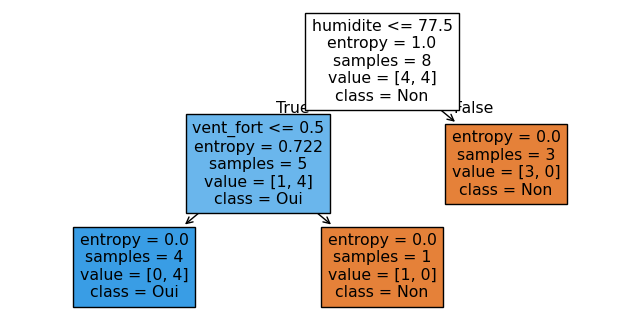

In [13]:
import numpy as np, pandas as pd
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, export_text, plot_tree
import matplotlib.pyplot as plt

X8 = pd.DataFrame({"ciel_soleil": [int(j["ciel"] == "Soleil") for j in jours],
                   "humidite": [j["humidite"] for j in jours],
                   "vent_fort": [int(j["vent"] == "Fort") for j in jours]})
y8 = [j["joue"] for j in jours]
arbre_sk = DecisionTreeClassifier(criterion="entropy", max_depth=2, random_state=0).fit(X8, y8)
print(export_text(arbre_sk, feature_names=list(X8.columns)))
demain_sk = pd.DataFrame([{"ciel_soleil": 1, "humidite": 72, "vent_fort": 1}])
print("Demain →", arbre_sk.predict(demain_sk)[0])
arbre_gini = DecisionTreeClassifier(criterion="gini", random_state=0).fit(X8, y8)
print("Avec Gini, même racine :", export_text(arbre_gini, feature_names=list(X8.columns)).splitlines()[0])

plt.figure(figsize=(8, 4))
plot_tree(arbre_sk, feature_names=list(X8.columns), class_names=list(arbre_sk.classes_), filled=True)
plt.show()

### Question 9 — Vérifier les gains de la racine avec scikit-learn
scikit-learn calcule l’entropie de chaque nœud (`tree_.impurity`) : on retrouve 1,00 à la racine et 0,722 dans le groupe « humidité ≤ 77,5 ». Le gain se retrouve à partir de ces impuretés et des effectifs (`tree_.n_node_samples`).

In [14]:
t = arbre_sk.tree_
gauche, droite = t.children_left[0], t.children_right[0]
gain_sk = t.impurity[0] - (t.n_node_samples[gauche] * t.impurity[gauche] + t.n_node_samples[droite] * t.impurity[droite]) / t.n_node_samples[0]
print(f"Racine : variable = {X8.columns[t.feature[0]]}, seuil = {t.threshold[0]}, entropie = {t.impurity[0]:.3f}")
print(f"Groupe gauche : entropie = {t.impurity[gauche]:.3f} ; gain de la racine = {gain_sk:.3f}")

# Même chose avec le critère Gini (défaut de scikit-learn)
tg = arbre_gini.tree_
gg, gd = tg.children_left[0], tg.children_right[0]
gain_gini_sk = tg.impurity[0] - (tg.n_node_samples[gg] * tg.impurity[gg] + tg.n_node_samples[gd] * tg.impurity[gd]) / tg.n_node_samples[0]
print(f"Gini : racine = {X8.columns[tg.feature[0]]} ≤ {tg.threshold[0]} ; Gini racine = {tg.impurity[0]:.3f} ; "
      f"Gini groupe gauche = {tg.impurity[gg]:.3f} ; gain = {gain_gini_sk:.3f}")

Racine : variable = humidite, seuil = 77.5, entropie = 1.000
Groupe gauche : entropie = 0.722 ; gain de la racine = 0.549
Gini : racine = humidite ≤ 77.5 ; Gini racine = 0.500 ; Gini groupe gauche = 0.320 ; gain = 0.300


### Question 10 — `DecisionTreeRegressor` pour les glaces

In [15]:
reg = DecisionTreeRegressor(max_depth=1).fit(np.array(temperatures).reshape(-1, 1), ventes)
print(export_text(reg, feature_names=["temperature"]))
print("Ventes prédites à 28 °C :", reg.predict([[28]])[0], "TND")

|--- temperature <= 22.00
|   |--- value: [50.00]
|--- temperature >  22.00
|   |--- value: [220.00]

Ventes prédites à 28 °C : 220.0 TND


### Question 11 — Exemple ID3 : gains avec `mutual_info_classif`, et arbre binaire de scikit-learn

- Le gain d’information d’une variable est exactement l’**information mutuelle** entre cette variable et la cible. `mutual_info_classif` la calcule en *nats* (logarithme népérien) ; on divise par $\ln 2$ pour l’avoir en *bits* (log₂).
- scikit-learn ne sait faire que des arbres **binaires** . Sur les 14 jours codés en 0 / 1, il lui faut **4 niveaux et 7 feuilles**, contre 2 niveaux et 5 feuilles pour ID3 .

In [16]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import OrdinalEncoder

D14 = pd.DataFrame(jours14)
X_cat = OrdinalEncoder().fit_transform(D14[variables])
gains_sk = mutual_info_classif(X_cat, D14["jouer"], discrete_features=True) / np.log(2)
for v, g in zip(variables, gains_sk):
    print(f"gain {v:<12} scikit-learn = {g:.3f}   Python pur = {gains14[v]:.3f}")

X_oh = pd.get_dummies(D14[variables]).astype(int)          # codage 0 / 1 de chaque catégorie
cart = DecisionTreeClassifier(criterion="entropy", random_state=0).fit(X_oh, D14["jouer"])
print(f"\nArbre binaire scikit-learn : profondeur = {cart.get_depth()}, feuilles = {cart.get_n_leaves()}")

gain ciel         scikit-learn = 0.247   Python pur = 0.247
gain temperature  scikit-learn = 0.029   Python pur = 0.029
gain humidite     scikit-learn = 0.152   Python pur = 0.152
gain vent         scikit-learn = 0.048   Python pur = 0.048

Arbre binaire scikit-learn : profondeur = 4, feuilles = 7


---
# Partie C — Comparaison et validation
### Question 12 — Les résultats concordent-ils ?

In [17]:
lignes = [
    ("Ex.1 question racine", arbre["question"], f"{X8.columns[t.feature[0]]} ≤ {t.threshold[0]}"),
    ("Ex.1 gain racine (entropie)", round(gains_racine["humidité ≤ 77.5 ?"], 3), round(gain_sk, 3)),
    ("Ex.1 gain racine (Gini)", round(gains_gini_racine["humidité ≤ 77.5 ?"], 3), round(gain_gini_sk, 3)),
    ("Ex.1 question niveau 2", arbre["oui"]["question"], X8.columns[t.feature[gauche]]),
    ("Ex.1 prédiction demain", predire(arbre, demain), arbre_sk.predict(demain_sk)[0]),
    ("Ex.2 seuil", t_best, reg.tree_.threshold[0]),
    ("Ex.2 ventes à 28 °C", prediction_28, reg.predict([[28]])[0]),
] + [(f"Ex.3 gain {v}", round(gains14[v], 3), round(g, 3)) for v, g in zip(variables, gains_sk)]
display(pd.DataFrame(lignes, columns=["Grandeur", "Python pur", "scikit-learn"]))

assert abs(gain_sk - gains_racine["humidité ≤ 77.5 ?"]) < 1e-9
assert abs(gain_gini_sk - gains_gini_racine["humidité ≤ 77.5 ?"]) < 1e-9
assert t.threshold[0] == float(arbre["question"].split("≤ ")[1].split(" ")[0]) and X8.columns[t.feature[gauche]] == "vent_fort"
assert reg.tree_.threshold[0] == t_best and reg.predict([[28]])[0] == prediction_28
assert np.allclose(gains_sk, [gains14[v] for v in variables])
assert all(arbre_sk.predict(X8) == np.array(y8))
assert all(predire(arbre, j) == p for j, p in zip(jours, arbre_sk.predict(X8)))
print("✅ Python pur = scikit-learn : mêmes questions, mêmes seuils, mêmes gains (entropie et Gini), mêmes prédictions")

,Grandeur,Python pur,scikit-learn
0,Ex.1 question racine,humidité ≤ 77.5 ?,humidite ≤ 77.5
1,Ex.1 gain racine (entropie),0.549,0.549
2,Ex.1 gain racine (Gini),0.3,0.3
3,Ex.1 question niveau 2,vent fort ?,vent_fort
4,Ex.1 prédiction demain,Non,Non
5,Ex.2 seuil,22.0,22.0
6,Ex.2 ventes à 28 °C,220.0,220.0
7,Ex.3 gain ciel,0.247,0.247
8,Ex.3 gain temperature,0.029,0.029
9,Ex.3 gain humidite,0.152,0.152


✅ Python pur = scikit-learn : mêmes questions, mêmes seuils, mêmes gains (entropie et Gini), mêmes prédictions


## Conclusion

| Ce qu’on a comparé (Python pur ↔ scikit-learn) | Résultat |
|---|---|
| Ex.1 : question de la racine (Humidité ≤ 77,5), son gain avec l’entropie et avec Gini | ✅ identiques |
| Ex.1 : question du niveau 2 (Vent fort ?), prédictions sur les 8 jours et pour demain | ✅ identiques |
| Ex.2 : seuil de coupure (22 °C) et ventes prédites à 28 °C | ✅ identiques |
| Ex.3 : gains d’information des 4 variables (`mutual_info_classif`) | ✅ identiques |
| Ex.3 : ID3 (2 niveaux, 5 feuilles) ↔ arbre binaire de scikit-learn (4 niveaux, 7 feuilles) | même tâche, structures différentes |

**À retenir**
- Un arbre apprend des **questions** et des **feuilles**, choisies une à une sans retour en arrière (algorithme glouton).
- Classification : entropie ou Gini ; régression : SSE. Feuille = classe majoritaire ou moyenne.
- scikit-learn ne construit que des arbres binaires : les variables à catégories doivent être codées en 0 / 1.